# The v5 engine vs the v4 engine

The shipped v5 engine — the v4 search plus the forced-win layer — against the v4 engine it extends, over every decision point of the same recorded game.

## The two engines

Both share the evaluator and the alpha-beta core; v5 wraps them with the forced-win layer, budgeted deepening and the defence screen.

In [1]:
import os
import sys
import time
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tuning" / "default.json").is_file())
os.environ["WEIGHTS_FILE"] = str(ROOT / "tuning" / "winner.json")
sys.path.insert(0, str(ROOT / "tuning"))

import harness
from connect6.search import search_alpha_beta_with_quiescence
from connect6.vcf import search_v5

print(f"weights pinned to {os.environ['WEIGHTS_FILE']} (the shipped champion)")


weights pinned to /Users/e.butovka/Documents/MyProjects/Connect6Engine/tuning/winner.json (the shipped champion)


## The common trajectory

The recorded game is benchmarks/trajectory.json, a 48-move self-play shared by the version measurements.

In [2]:
import json

record = json.loads((ROOT / "benchmarks" / "trajectory.json").read_text())
history = record["history"]
assert record["outcome"] == {"winner": None, "plies": 48}
assert history[0] == "JJ" and len(history) == 49
print("common trajectory loaded: benchmarks/trajectory.json — 48 decision points, no win inside the cap")


rows = harness.analyze_history(history, [("v4", search_alpha_beta_with_quiescence), ("v5", search_v5)], 3)
per_prefix = {}
for row in rows:
    per_prefix.setdefault(row.prefix, {})[row.name] = row
positions = sorted(per_prefix)
n = len(positions)

totals = {name: sum(per_prefix[p][name].nodes for p in positions) for name in ("v4", "v5")}
changes = sum(1 for p in positions if per_prefix[p]["v4"].move != per_prefix[p]["v5"].move)
flips = sum(1 for p in positions if (abs(per_prefix[p]["v4"].score) >= 20000) != (abs(per_prefix[p]["v5"].score) >= 20000))
ones = [p for p in positions if per_prefix[p]["v5"].nodes == 1]
peak = max(positions, key=lambda p: per_prefix[p]["v5"].nodes)
print(f"{'engine':6s} {'total nodes':>12s} {'mean/position':>13s} {'peak':>8s}")
for name in ("v4", "v5"):
    top = max(per_prefix[p][name].nodes for p in positions)
    print(f"{name:6s} {totals[name]:12,d} {totals[name] // n:13,d} {top:8,d}")
print(f"move changes: {changes}/{n}   verdict-band flips: {flips}/{n}   v5 node peak: prefix {peak}")
print(f"one-node stage-1 answers: {ones}")
for p in ones:
    row = per_prefix[p]
    print(f"  prefix {p:2d}: v5 answers {row['v5'].move} at {row['v5'].score} in one node; "
          f"v4 scored {row['v4'].score} in {row['v4'].nodes:,} nodes")

common trajectory loaded: benchmarks/trajectory.json — 48 decision points, no win inside the cap


engine  total nodes mean/position     peak
v4          320,038         6,667   40,262
v5        1,415,330        29,486  233,374
move changes: 35/48   verdict-band flips: 6/48   v5 node peak: prefix 34
one-node stage-1 answers: [42, 44, 45, 46, 47]
  prefix 42: v5 answers IMJM at 20000 in one node; v4 scored 441 in 9,689 nodes
  prefix 44: v5 answers IMJM at 20000 in one node; v4 scored 1961 in 4,808 nodes
  prefix 45: v5 answers FKFJ at -20000 in one node; v4 scored -278 in 11,979 nodes
  prefix 46: v5 answers IMJM at 20000 in one node; v4 scored 474 in 21,722 nodes
  prefix 47: v5 answers FKFJ at -20000 in one node; v4 scored -561 in 9,514 nodes


In [3]:
EXPECTED_V5 = {"v4_nodes": 320038, "v5_nodes": 1415330, "changes": 35, "flips": 6, "ones": [42, 44, 45, 46, 47], "v5_peak": 233374}
assert totals["v4"] == EXPECTED_V5["v4_nodes"]
assert totals["v5"] == EXPECTED_V5["v5_nodes"]
assert changes == EXPECTED_V5["changes"]
assert flips == EXPECTED_V5["flips"]
assert ones == EXPECTED_V5["ones"]
assert max(per_prefix[p]["v5"].nodes for p in positions) == EXPECTED_V5["v5_peak"]
assert per_prefix[36]["v5"].score == 20000 and per_prefix[36]["v5"].nodes == 70
print("the layer's costs and verdicts reproduce exactly (nodes, changes, flips, one-node answers)")


the layer's costs and verdicts reproduce exactly (nodes, changes, flips, one-node answers)


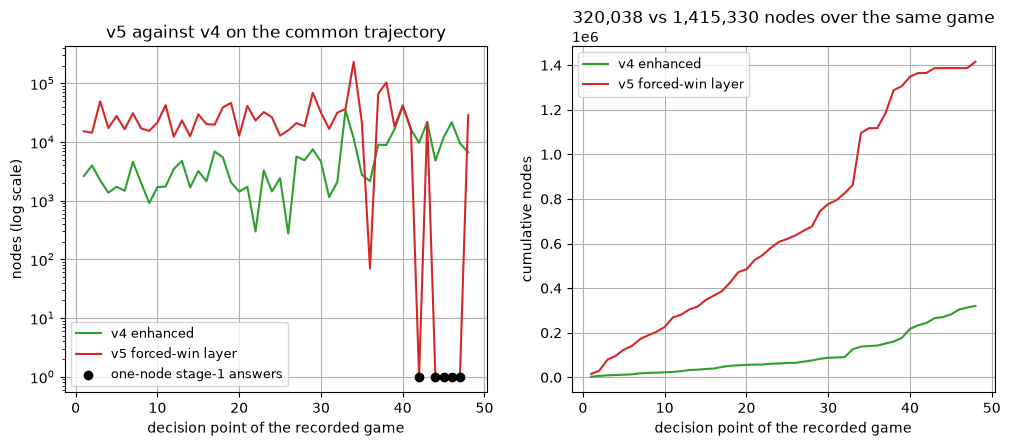

In [4]:
import matplotlib.pyplot as plt

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax.plot(positions, [per_prefix[p]["v4"].nodes for p in positions], color="tab:green", label="v4 enhanced")
ax.plot(positions, [per_prefix[p]["v5"].nodes for p in positions], color="tab:red", label="v5 forced-win layer")
ax.scatter(ones, [1] * len(ones), color="black", zorder=3, label="one-node stage-1 answers")
ax.set_yscale("log")
ax.set_xlabel("decision point of the recorded game")
ax.set_ylabel("nodes (log scale)")
ax.set_title("v5 against v4 on the common trajectory")
ax.grid(True)
ax.legend(fontsize=9)
ax2.plot(positions, [sum(per_prefix[q]["v4"].nodes for q in positions[:i + 1]) for i, p in enumerate(positions)], color="tab:green", label="v4 enhanced")
ax2.plot(positions, [sum(per_prefix[q]["v5"].nodes for q in positions[:i + 1]) for i, p in enumerate(positions)], color="tab:red", label="v5 forced-win layer")
ax2.set_xlabel("decision point of the recorded game")
ax2.set_ylabel("cumulative nodes")
ax2.set_title("320,038 vs 1,415,330 nodes over the same game")
ax2.grid(True)
ax2.legend(fontsize=9)
plt.show()


## The node cost, decomposed

Every decision point answered twice — by v4 and by v5 — with the totals per engine.

## Wall time against node counts

Node counts are the exact record; wall time is indicative only.

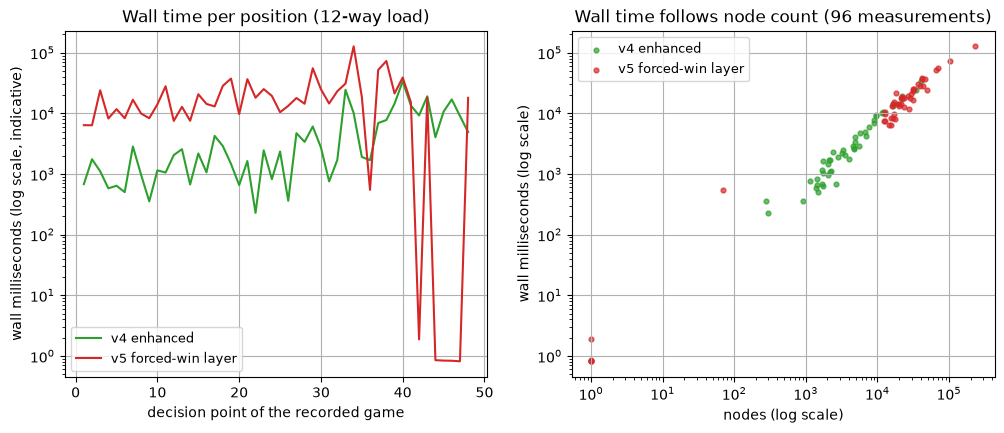

In [5]:
import matplotlib.pyplot as plt

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax.plot(positions, [per_prefix[p]["v4"].ms for p in positions], color="tab:green", label="v4 enhanced")
ax.plot(positions, [per_prefix[p]["v5"].ms for p in positions], color="tab:red", label="v5 forced-win layer")
ax.set_yscale("log")
ax.set_xlabel("decision point of the recorded game")
ax.set_ylabel("wall milliseconds (log scale, indicative)")
ax.set_title("Wall time per position (12-way load)")
ax.grid(True)
ax.legend(fontsize=9)

v4_points = [(per_prefix[p]["v4"].nodes, per_prefix[p]["v4"].ms) for p in positions]
v5_points = [(per_prefix[p]["v5"].nodes, per_prefix[p]["v5"].ms) for p in positions]
ax2.scatter(*zip(*v4_points), s=12, color="tab:green", label="v4 enhanced", alpha=0.7)
ax2.scatter(*zip(*v5_points), s=12, color="tab:red", label="v5 forced-win layer", alpha=0.7)
ax2.set_xscale("log")
ax2.set_yscale("log")
ax2.set_xlabel("nodes (log scale)")
ax2.set_ylabel("wall milliseconds (log scale)")
ax2.set_title("Wall time follows node count (96 measurements)")
ax2.grid(True)
ax2.legend(fontsize=9)
plt.show()

## The floor ladder

The flip prefixes at floors 3, 4 and 5, both engines: whether a deeper floor closes the gap.

In [6]:
import concurrent.futures

FLIP_STARTS = [36, 42, 44, 45, 46, 47]
FLOORS = (3, 4, 5)

floor_tasks = [
    (history, p, name, search, floor)
    for p in FLIP_STARTS
    for floor in FLOORS
    for name, search in (("v4", search_alpha_beta_with_quiescence), ("v5", search_v5))
]
with concurrent.futures.ProcessPoolExecutor(max_workers=12) as pool:
    floor_rows = list(pool.map(harness._analysis_worker, floor_tasks))
floor_probe = {}
for task, row in zip(floor_tasks, floor_rows):
    floor_probe[(task[1], task[4], task[2])] = row

print(f"{'start':>5} {'floor':>5} | {'v4 nodes':>9} {'growth':>7} {'v4 ms':>9} {'score':>6} | "
      f"{'v5 nodes':>8} {'v5 ms':>8} {'score':>6} | node cut")
for p in FLIP_STARTS:
    for floor in FLOORS:
        v4 = floor_probe[(p, floor, "v4")]
        v5 = floor_probe[(p, floor, "v5")]
        growth = "-" if floor == 3 else f"x{v4.nodes / floor_probe[(p, floor - 1, 'v4')].nodes:.1f}"
        print(f"{p:>5} {floor:>5} | {v4.nodes:>9,d} {growth:>7} {v4.ms:>9.0f} {v4.score:>6} | "
              f"{v5.nodes:>8,d} {v5.ms:>8.1f} {v5.score:>6} | x{v4.nodes / v5.nodes:>9,.0f}")
    print()

start floor |  v4 nodes  growth     v4 ms  score | v5 nodes    v5 ms  score | node cut
   36     3 |     2,147       -      1713    610 |       70    540.2  20000 | x       31
   36     4 |    36,525   x17.0     29262    381 |       70    587.2  20000 | x      522
   36     5 |   165,004    x4.5    109671    443 |       70    550.6  20000 | x    2,357

   42     3 |     9,689       -      9578    441 |        1      1.9  20000 | x    9,689
   42     4 |    21,386    x2.2     18952    -37 |        1      0.9  20000 | x   21,386
   42     5 |    65,161    x3.0     53992    322 |        1      0.8  20000 | x   65,161

   44     3 |     4,808       -      4378   1961 |        1      0.8  20000 | x    4,808
   44     4 |    33,345    x6.9     29835    236 |        1      0.9  20000 | x   33,345
   44     5 |   195,267    x5.9    130377    321 |        1      0.9  20000 | x  195,267

   45     3 |    11,979       -     10474   -278 |        1      1.1 -20000 | x   11,979
   45     4 |    34,

In [7]:
EXPECTED_FLOOR = {
    (36, 3, "v4"): (2147, 610, "GIHL"), (36, 4, "v4"): (36525, 381, "PJLP"), (36, 5, "v4"): (165004, 443, "JNKO"),
    (42, 3, "v4"): (9689, 441, "EMJP"), (42, 4, "v4"): (21386, -37, "EMJP"), (42, 5, "v4"): (65161, 322, "EMJP"),
    (44, 3, "v4"): (4808, 1961, "PJLP"), (44, 4, "v4"): (33345, 236, "HNPJ"), (44, 5, "v4"): (195267, 321, "HNFK"),
    (45, 3, "v4"): (11979, -278, "KQPG"), (45, 4, "v4"): (34302, 144, "KQPG"), (45, 5, "v4"): (79670, 156, "KQPG"),
    (46, 3, "v4"): (21722, 474, "FOIM"), (46, 4, "v4"): (52325, -48, "HNFO"), (46, 5, "v4"): (122407, 156, "FOOH"),
    (47, 3, "v4"): (9514, -561, "JMHO"), (47, 4, "v4"): (29801, -210, "JMKP"), (47, 5, "v4"): (89361, -284, "JMKP"),
    (36, 3, "v5"): (70, 20000, "JRQJ"), (36, 4, "v5"): (70, 20000, "JRQJ"), (36, 5, "v5"): (70, 20000, "JRQJ"),
    (42, 3, "v5"): (1, 20000, "IMJM"), (42, 4, "v5"): (1, 20000, "IMJM"), (42, 5, "v5"): (1, 20000, "IMJM"),
    (44, 3, "v5"): (1, 20000, "IMJM"), (44, 4, "v5"): (1, 20000, "IMJM"), (44, 5, "v5"): (1, 20000, "IMJM"),
    (45, 3, "v5"): (1, -20000, "FKFJ"), (45, 4, "v5"): (1, -20000, "FKFJ"), (45, 5, "v5"): (1, -20000, "FKFJ"),
    (46, 3, "v5"): (1, 20000, "IMJM"), (46, 4, "v5"): (1, 20000, "IMJM"), (46, 5, "v5"): (1, 20000, "IMJM"),
    (47, 3, "v5"): (1, -20000, "FKFJ"), (47, 4, "v5"): (1, -20000, "FKFJ"), (47, 5, "v5"): (1, -20000, "FKFJ"),
}
for key, (nodes, score, move) in EXPECTED_FLOOR.items():
    row = floor_probe[key]
    assert (row.nodes, row.score, row.move) == (nodes, score, move), key
for p in FLIP_STARTS:
    for floor in FLOORS:
        assert abs(floor_probe[(p, floor, "v4")].score) < 20000, (p, floor, "v4 must stay quiet")
        assert abs(floor_probe[(p, floor, "v5")].score) >= 20000, (p, floor, "v5 must prove the win")
print("the floor ladder reproduces the verdict tournament's probe exactly: "
      "v4 quiet at every floor, v5 floor-invariant at one node (70 on prefix 36)")

the floor ladder reproduces the verdict tournament's probe exactly: v4 quiet at every floor, v5 floor-invariant at one node (70 on prefix 36)


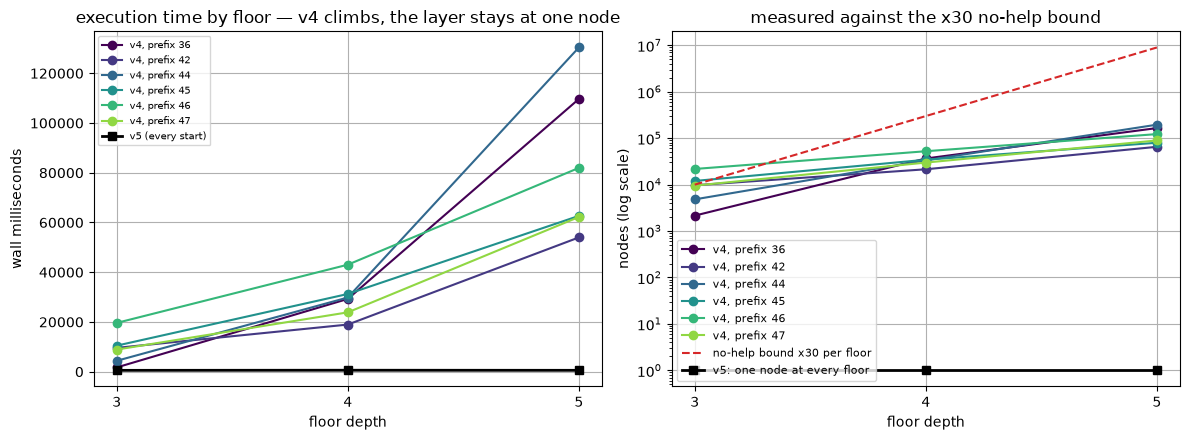

In [8]:
import matplotlib.pyplot as plt

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
colors = plt.cm.viridis([i / 6 for i in range(6)])
for i, p in enumerate(FLIP_STARTS):
    v4_ms = [floor_probe[(p, f, "v4")].ms for f in FLOORS]
    v4_nodes = [floor_probe[(p, f, "v4")].nodes for f in FLOORS]
    ax.plot(FLOORS, v4_ms, marker="o", color=colors[i], label=f"v4, prefix {p}")
    ax2.semilogy(FLOORS, v4_nodes, marker="o", color=colors[i], label=f"v4, prefix {p}")
v5_ms = [floor_probe[(36, f, "v5")].ms for f in FLOORS]
ax.plot(FLOORS, v5_ms, marker="s", color="black", linewidth=2, label="v5 (every start)")
ax.set_xlabel("floor depth")
ax.set_ylabel("wall milliseconds")
ax.set_title("execution time by floor — v4 climbs, the layer stays at one node")
ax.set_xticks(FLOORS)
ax.grid(True)
ax.legend(fontsize=7)

mean_floor3 = sum(floor_probe[(p, 3, "v4")].nodes for p in FLIP_STARTS) / len(FLIP_STARTS)
no_help = [mean_floor3 * 30 ** (f - 3) for f in FLOORS]
ax2.semilogy(FLOORS, no_help, linestyle="--", color="tab:red", label="no-help bound x30 per floor")
ax2.semilogy(FLOORS, [1] * len(FLOORS), marker="s", color="black", linewidth=2, label="v5: one node at every floor")
ax2.set_xlabel("floor depth")
ax2.set_ylabel("nodes (log scale)")
ax2.set_title("measured against the x30 no-help bound")
ax2.set_xticks(FLOORS)
ax2.grid(True)
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Iterative deepening under the budget

The budgeted deepening loop: search the floor, then re-search one ply deeper per step while the node budget lasts.

In [9]:
deepening = harness.probe_deepening(history, jobs=12)

floor_total = sum(steps[0].nodes for steps in deepening.values())
stage2_total = sum(sum(s.nodes for s in steps) for steps in deepening.values())
assert floor_total == totals["v4"]  # the loop's floor iteration is exactly v4's fixed tree

def band(score):
    return abs(score) >= 20000

stage1_positions = [36, 42, 44, 45, 46, 47]  # stage-1 positions: the forced-win search answers these before the loop runs
skipped = sum(sum(s.nodes for s in deepening[p]) for p in stage1_positions)

transitions = {"floor->d4": [0, 0, 0], "d4->d5": [0, 0, 0]}  # kept, changed, flipped
for steps in deepening.values():
    for i in range(1, len(steps)):
        key = "floor->d4" if i == 1 else "d4->d5"
        if band(steps[i].score) != band(steps[i - 1].score):
            transitions[key][2] += 1
        elif steps[i].move != steps[i - 1].move:
            transitions[key][1] += 1
        else:
            transitions[key][0] += 1

final_changes = sum(1 for s in deepening.values() if s[-1].move != s[0].move)
final_flips = sum(1 for s in deepening.values() if band(s[-1].score) != band(s[0].score))
d4_nodes = [s.nodes for steps in deepening.values() for s in steps if s.depth == 4]
d5_nodes = [s.nodes for steps in deepening.values() for s in steps if s.depth == 5]
reached_d4, reached_d5 = len(d4_nodes), len(d5_nodes)
floor_only = sum(1 for steps in deepening.values() if len(steps) == 1)

EXPECTED_DEEPENING = {
    "total": 1621464, "reached_d4": 42, "reached_d5": 9, "floor_only": 6,
    "d4_mean": 26021, "d5_mean": 23170, "skipped": 215218,
    "floor_to_d4": (11, 31, 0), "d4_to_d5": (5, 4, 0),
    "final_changes": 30, "final_flips": 0, "ledger_gap": 9084,
}
assert stage2_total == EXPECTED_DEEPENING["total"]
assert (reached_d4, reached_d5, floor_only) == (
    EXPECTED_DEEPENING["reached_d4"], EXPECTED_DEEPENING["reached_d5"], EXPECTED_DEEPENING["floor_only"])
assert sum(d4_nodes) // len(d4_nodes) == EXPECTED_DEEPENING["d4_mean"]
assert sum(d5_nodes) // len(d5_nodes) == EXPECTED_DEEPENING["d5_mean"]
assert skipped == EXPECTED_DEEPENING["skipped"]
assert tuple(transitions["floor->d4"]) == EXPECTED_DEEPENING["floor_to_d4"]
assert tuple(transitions["d4->d5"]) == EXPECTED_DEEPENING["d4_to_d5"]
assert (final_changes, final_flips) == (EXPECTED_DEEPENING["final_changes"], EXPECTED_DEEPENING["final_flips"])
assert totals["v5"] - (stage2_total - skipped) == EXPECTED_DEEPENING["ledger_gap"]

print(f"stage 2 in isolation: {stage2_total:,} nodes over 48 decision points "
      f"(the floor alone is {floor_total:,} — v4's whole game)")
print(f"deepening reached: d4 on {reached_d4}/48 (mean {sum(d4_nodes) // len(d4_nodes):,} nodes), "
      f"d5 on {reached_d5}/48 (mean {sum(d5_nodes) // len(d5_nodes):,} nodes); "
      f"{floor_only} positions stop at the floor")
print(f"per-step transitions (kept, changed, flipped): floor->d4 {tuple(transitions['floor->d4'])}, "
      f"d4->d5 {tuple(transitions['d4->d5'])}")
print(f"floor->final: {final_changes} quiet move changes, {final_flips} verdict flips — "
      f"all six of v5's flips over v4 are stage-1 proofs")
print(f"ledger: probe {stage2_total:,} - never-run {skipped:,} + gap {EXPECTED_DEEPENING['ledger_gap']:,} "
      f"(six stage-1 answers = 75 nodes, stage-1 misses + screens = 9,009) = v5's {totals['v5']:,}")

stage 2 in isolation: 1,621,464 nodes over 48 decision points (the floor alone is 320,038 — v4's whole game)
deepening reached: d4 on 42/48 (mean 26,021 nodes), d5 on 9/48 (mean 23,170 nodes); 6 positions stop at the floor
per-step transitions (kept, changed, flipped): floor->d4 (11, 31, 0), d4->d5 (5, 4, 0)
floor->final: 30 quiet move changes, 0 verdict flips — all six of v5's flips over v4 are stage-1 proofs
ledger: probe 1,621,464 - never-run 215,218 + gap 9,084 (six stage-1 answers = 75 nodes, stage-1 misses + screens = 9,009) = v5's 1,415,330


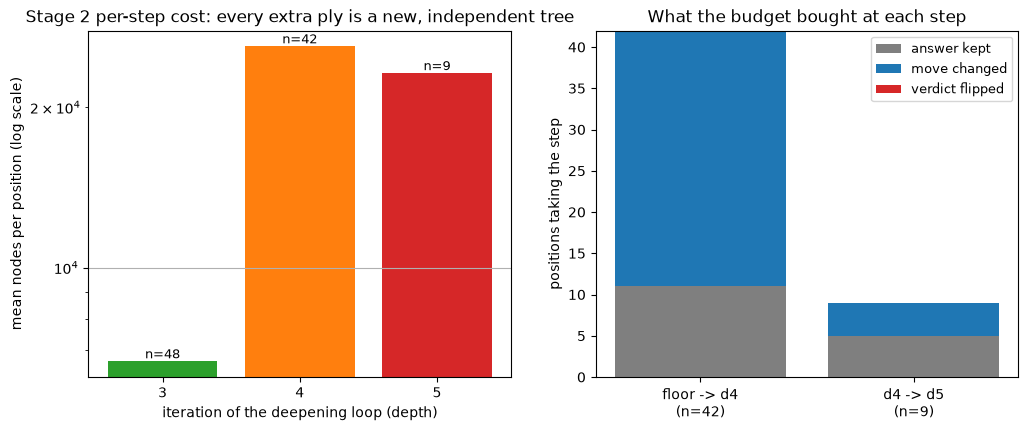

In [10]:
import matplotlib.pyplot as plt

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
depths = (3, 4, 5)
step_nodes = {d: [s.nodes for steps in deepening.values() for s in steps if s.depth == d] for d in depths}
means = [sum(v) / len(v) for v in step_nodes.values()]
bars = ax.bar([str(d) for d in depths], means, color=["tab:green", "tab:orange", "tab:red"])
ax.set_yscale("log")
for bar, d in zip(bars, depths):
    ax.annotate(f"n={len(step_nodes[d])}", (bar.get_x() + bar.get_width() / 2, means[d - 3]),
                ha="center", va="bottom", fontsize=9)
ax.set_xlabel("iteration of the deepening loop (depth)")
ax.set_ylabel("mean nodes per position (log scale)")
ax.set_title("Stage 2 per-step cost: every extra ply is a new, independent tree")
ax.grid(True, axis="y")

labels = [f"floor -> d4\n(n={reached_d4})", f"d4 -> d5\n(n={reached_d5})"]
kept = [transitions["floor->d4"][0], transitions["d4->d5"][0]]
changed = [transitions["floor->d4"][1], transitions["d4->d5"][1]]
flipped = [transitions["floor->d4"][2], transitions["d4->d5"][2]]
ax2.bar(labels, kept, color="tab:gray", label="answer kept")
ax2.bar(labels, changed, bottom=kept, color="tab:blue", label="move changed")
ax2.bar(labels, flipped, bottom=[k + c for k, c in zip(kept, changed)], color="tab:red", label="verdict flipped")
ax2.set_ylabel("positions taking the step")
ax2.set_title("What the budget bought at each step")
ax2.legend(fontsize=9)
plt.show()

### The loop's step ledger

Per-step means and totals of the deepening loop.

In [11]:
step_totals = {d: sum(s.nodes for steps in deepening.values() for s in steps if s.depth == d) for d in (3, 4, 5)}
step_counts = {d: sum(1 for steps in deepening.values() for s in steps if s.depth == d) for d in (3, 4, 5)}
step_means = {d: step_totals[d] / step_counts[d] for d in (3, 4, 5)}
loop_total = sum(step_totals.values())
assert loop_total == EXPECTED_DEEPENING["total"]
assert step_counts[4] == EXPECTED_DEEPENING["reached_d4"] and step_counts[5] == EXPECTED_DEEPENING["reached_d5"]
assert step_totals[3] == totals["v4"]

print(f"{'step':>9} {'positions':>9} {'total nodes':>12} {'mean nodes':>12} {'growth':>7} {'share':>6}")
previous = None
for d in (3, 4, 5):
    growth = "-" if previous is None else f"x{step_means[d] / previous:.2f}"
    print(f"depth {d:>2} {step_counts[d]:>9} {step_totals[d]:>12,d} {step_means[d]:>12,.1f} {growth:>7} "
          f"{100 * step_totals[d] / loop_total:>5.1f}%")
    previous = step_means[d]
print(f"{'loop':>9} {48:>9} {loop_total:>12,d} {'':>12} {'':>7} {'100.0%':>6}")
print()
print("the floor step is exactly v4's whole game (320,038 nodes); the budget's extra depth "
      f"is the remaining {(loop_total - step_totals[3]) / step_totals[3]:.1f}x spent on top of it")

     step positions  total nodes   mean nodes  growth  share
depth  3        48      320,038      6,667.5       -  19.7%
depth  4        42    1,092,894     26,021.3   x3.90  67.4%
depth  5         9      208,532     23,170.2   x0.89  12.9%
     loop        48    1,621,464                      100.0%

the floor step is exactly v4's whole game (320,038 nodes); the budget's extra depth is the remaining 4.1x spent on top of it


## Reading the results

The layer finds wins the fixed-depth search never recognizes; the cost is real but unevenly distributed.